# 2 · DDP and iLQR: from the cost to working Python

**Question:** How does the solver find a base torque sequence that swings the robot upright?

This notebook explains rollout, cost, derivatives, the backward pass, line search,
regularization, stopping, and final feedback gains. It then runs both algorithms.
Estimated study time: 35–50 minutes. The first optimization includes compilation;
execution time depends on your computer.

Run cells from top to bottom using **Kernel → Restart Kernel and Run All Cells**.
Each notebook starts independently and imports the real project files. Python 3 with
the packages in `requirements-notebooks.txt` is required; see `README.txt` in this folder.
The delivered outputs were executed, not typed example results. Rerunning updates them.

In [1]:
from pathlib import Path
import sys, inspect, json, csv
from dataclasses import asdict, replace
import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Code, HTML, Image

# Works when Jupyter starts in this notebook folder, the project root,
# or the original workspace. No Windows-specific absolute path is needed.
def find_project():
    for parent in (Path.cwd(), *Path.cwd().parents):
        for candidate in (parent, parent / 'pendubot_simulation',
                          parent / 'Pendubot_Opt_Control',
                          parent / 'outputs' / 'pendubot_simulation',
                          parent / 'outputs' / 'Pendubot_Opt_Control'):
            if (candidate / 'pendubot.py').is_file():
                return candidate.resolve()
    raise FileNotFoundError('Keep notebooks/ inside the Pendubot project folder.')

PROJECT = find_project()
sys.path.insert(0, str(PROJECT))
from pendubot import Config, Solver, X0, GOAL, mass_matrix, dynamics, rk4, energy

def show_source(obj):
    # Display the actual implementation rather than a separately maintained copy.
    display(Code(inspect.getsource(obj), language='python'))

def show_table(rows, columns=None):
    if not rows:
        print('No rows.'); return
    columns = columns or list(rows[0])
    def fmt(value):
        if isinstance(value, (float, np.floating)):
            return f'{value:.6g}'
        return str(value)
    lines = ['| ' + ' | '.join(columns) + ' |',
             '| ' + ' | '.join(['---'] * len(columns)) + ' |']
    lines += ['| ' + ' | '.join(fmt(row.get(c, '')) for c in columns) + ' |'
              for row in rows]
    display(Markdown('\n'.join(lines)))

plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True,
                     'grid.alpha': 0.22, 'font.size': 11})
print('Python:', sys.version.split()[0], '| JAX:', jax.__version__)
print('JAX uses 64-bit arithmetic:', jax.config.x64_enabled)
print('Project located successfully.')

Python: 3.14.7 | JAX: 0.12.0.1
JAX uses 64-bit arithmetic: True
Project located successfully.


## 1. The finite-horizon problem

The decision is $u_0,\ldots,u_{N-1}$, subject to $x_{k+1}=F(x_k,u_k)$.
Define the **unwrapped** error $e_k=x_k-x_{goal}$. The implemented objective is

$$J=\frac12 e_N^TQ_N e_N+\frac{\Delta t}{2}\sum_{k=0}^{N-1}
\left(e_k^T Q e_k+r u_k^2\right).$$

The running sum excludes $e_N$; the terminal penalty treats it separately.
`Q` and `QN` are diagonal, `r > 0` penalizes torque. A soft terminal penalty
does not impose an exact terminal state. There is **no hard torque bound**.
An increased `r` discourages torque but does not guarantee a peak limit.

In [2]:
# These are the parameters to change for your own experiments.
cfg = Config(duration=6., dt=0.02, max_iterations=1500,
             q=(1., 1., .1, .1), q_terminal=(2000., 2000., 200., 200.), r=.01)
solver = Solver(cfg)
t_control = np.arange(cfg.n)*cfg.dt
u_initial = (4*np.sin(np.pi*t_control))[:, None]  # 2 s period; a starting guess, not a controller
x_initial = solver.rollout(jnp.asarray(u_initial))
print('Control shape:', u_initial.shape, '| State shape:', x_initial.shape)
show_source(Solver._cost)

Control shape: (300, 1) | State shape: (301, 4)


def _cost(self, x, u):
        e = x - GOAL  # Deliberately unwrapped: exactly the specified quadratic cost.
        return 0.5*self.cfg.dt*(jnp.einsum('ni,ij,nj->', e[:-1], self.Q, e[:-1])
                                + self.cfg.r*jnp.sum(u*u)) + 0.5*e[-1]@self.QN@e[-1]

### Reading the vectorized cost
`e[:-1]` selects the running states. `einsum('ni,ij,nj->', ...)` sums
$e_k^TQe_k$ across time. `sum(u*u)` sums squared scalar torques. The last
matrix product is the terminal quadratic. This cell calculates the same cost
with ordinary NumPy to make the indexing visible.

In [3]:
e = np.asarray(x_initial)-np.asarray(GOAL)
running_state = sum(ek @ np.diag(cfg.q) @ ek for ek in e[:-1])
running_torque = cfg.r*np.sum(u_initial**2)
terminal = .5*e[-1] @ np.diag(cfg.q_terminal) @ e[-1]
manual_cost = .5*cfg.dt*(running_state+running_torque)+terminal
print('Initial guess cost:', float(solver.cost(x_initial, jnp.asarray(u_initial))))
assert np.isclose(manual_cost, float(solver.cost(x_initial, jnp.asarray(u_initial))))

Initial guess cost: 11806.57443691757


## 2. `Solver.__init__`: build and compile the numerical tools

`step` performs one RK4 interval. `fine_step` is for execution checks. `packed`
joins the state and input into one five-vector for differentiation. `vmap`
batches derivatives over the horizon. `jit` compiles rollout, cost, backward,
and forward functions. `lax.scan` handles time recursion efficiently.

In [4]:
show_source(Solver.__init__)

def __init__(self, cfg=Config()):
        self.cfg = cfg
        self.Q = jnp.diag(jnp.array(cfg.q, dtype=jnp.float64))
        self.QN = jnp.diag(jnp.array(cfg.q_terminal, dtype=jnp.float64))
        self.step = jax.jit(lambda x, u: rk4(x, u, cfg.dt, cfg))
        self.fine_step = jax.jit(lambda x, u: jax.lax.fori_loop(
            0, 10, lambda _, z: rk4(z, u, cfg.dt/10, cfg), x))

        def packed(z):
            return rk4(z[:4], z[4:], cfg.dt, cfg)
        self.derivatives = jax.jit(jax.vmap(jax.jacfwd(packed)))
        self.hessians = jax.jit(jax.vmap(jax.jacfwd(jax.jacrev(packed))))
        self.rollout = jax.jit(self._rollout)
        self.cost = jax.jit(self._cost)
        self.backward = jax.jit(self._backward)
        self.forward = jax.jit(self._forward)

## 3. Rollout: propagate the current torque guess

`_rollout` passes the current state and `uk` into `step`. The scan returns all
next states; `concatenate` prepends the initial state. For $N=300$, there are
300 controls and 301 states. A zero input keeps the ideal downward robot at rest,
but the optimizer can change this input because the cost points toward upright.

In [5]:
show_source(Solver._rollout)

def _rollout(self, u, x0=X0):
        def body(x, uk):
            xn = self.step(x, uk)
            return xn, xn
        _, xs = jax.lax.scan(body, x0, u)
        return jnp.concatenate((x0[None, :], xs))

## 4. Backward pass: a local quadratic control problem

At each stage, form $H(x,u)=g(x,u)+V_{next}(F(x,u))$.
Let $A=F_x$, $B=F_u$. Then

$$H_x=g_x+A^TV_x,\quad H_u=g_u+B^TV_x,$$
$$H_{xx}=g_{xx}+A^TV_{xx}A+\sum_i(V_x)_iF_{i,xx},$$
$$H_{ux}=B^TV_{xx}A+\sum_i(V_x)_iF_{i,ux},\quad
H_{uu}=g_{uu}+B^TV_{xx}B+\sum_i(V_x)_iF_{i,uu}.$$

**Full DDP** retains the three dynamics-Hessian contractions.
**iLQR** sets those contractions to zero, while retaining the quadratic cost
and the $A,B,V_{xx}$ products. Both use the nonlinear RK4 dynamics in rollout.

In [6]:
z = jnp.concatenate((x_initial[:-1], jnp.asarray(u_initial)), axis=1)
jac = solver.derivatives(z)
hess = solver.hessians(z)
print('Time-batched Jacobians:', jac.shape)
print('Time-batched Hessians:', hess.shape)
print('A at sample 0:\n', np.asarray(jac[0, :, :4]))
print('B at sample 0:\n', np.asarray(jac[0, :, 4:]))

Time-batched Jacobians: (300, 4, 5)
Time-batched Hessians: (300, 4, 5, 5)
A at sample 0:
 [[ 9.97479903e-01  2.51762214e-03  1.99831829e-02  1.68171429e-05]
 [ 3.35682952e-03  9.90766244e-01  2.24228571e-05  1.99383371e-02]
 [-2.51762214e-01  2.51267286e-01  9.97479903e-01  2.51762214e-03]
 [ 3.35023048e-01 -9.21808310e-01  3.35682952e-03  9.90766244e-01]]
B at sample 0:
 [[ 0.00034235]
 [-0.00085563]
 [ 0.03418481]
 [-0.08541158]]


### Read `_backward` with the array shapes

| Name | Meaning | Shape per stage |
|---|---|---|
| `vx`, `vxx` | Next value gradient and Hessian | `(4,)`, `(4,4)` |
| `fz`, `fzz` | Packed dynamics derivatives | `(4,5)`, `(4,5,5)` |
| `a`, `b` | $F_x$, $F_u$ | `(4,4)`, `(4,1)` |
| `curvature` | $\sum_i(V_x)_i F_{i,zz}$ | `(5,5)` |
| `k`, `gain` | Feedforward correction and feedback gain | `(1,)`, `(1,4)` |

`einsum('i,ijk->jk', vx, fzz)` contracts the **output** axis of the dynamics Hessian.
The terminal values are $V_x=Q_N e_N$, $V_{xx}=Q_N$.
`reverse=True` runs the scan backward while returning gains in time order.

In [7]:
show_source(Solver._backward)

def _backward(self, x, u, jac, hess, mu):
        # z=[x,u]; Hessian tensor axes are [output,z,z].
        def body(carry, data):
            vx, vxx, valid = carry
            xi, ui, fz, fzz = data
            a, b = fz[:, :4], fz[:, 4:]
            lx = self.cfg.dt*self.Q@(xi-GOAL)
            lu = self.cfg.dt*self.cfg.r*ui
            hx, hu = lx+a.T@vx, lu+b.T@vx
            curvature = jnp.einsum('i,ijk->jk', vx, fzz)
            hxx = self.cfg.dt*self.Q + a.T@vxx@a + curvature[:4, :4]
            hux = b.T@vxx@a + curvature[4:, :4]
            huu = self.cfg.dt*self.cfg.r + (b.T@vxx@b)[0, 0] + curvature[4, 4]
            regularized = huu + mu
            ok = jnp.isfinite(regularized) & (regularized > 1e-10)
            denom = jnp.where(ok, regularized, 1.0)
            k, gain = hu/denom, hux/denom
            # Substitute du=-k-K dx in the original (unregularized) local model.
            nvx = hx - gain.T@hu - hux.T@k + (gain.T@k)*huu
            nvxx = hxx - gain.T@hux - hux.T@gain + gain.T@gain*huu
            nvxx = (nvxx+nvxx.T)/2
            return (nvx, nvxx, valid & ok & jnp.all(jnp.isfinite(nvxx))), (k, gain)
        terminal = (self.QN@(x[-1]-GOAL), self.QN, jnp.array(True))
        (_, _, valid), (ks, gains) = jax.lax.scan(
            body, terminal, (x[:-1], u, jac, hess), reverse=True)
        return ks, gains, valid

### Regularization and the sign convention

The single-input Hessian is a scalar. Use $D=H_{uu}+\mu$ with $D>0$,
$k=D^{-1}H_u$, $K=D^{-1}H_{ux}$. The policy is
$$u_{new}=\bar u-\alpha k-K(x_{new}-\bar x).$$
The code stores positive `k` and `gain` and **subtracts** them in the forward pass.
Its value recursion substitutes $\delta u=-k-K\delta x$ into the
**unregularized** local model, then symmetrizes $V_{xx}$. Checking `valid`
prevents using a non-finite or non-positive regularized control Hessian.

## 5. Forward pass and line search

The new rollout uses feedback on its deviation from the nominal state.
`alpha` scales only the feedforward correction. The solver tries 1, 1/2,
..., 1/128 and accepts a finite, strictly lower objective. An invalid backward
pass or unsuccessful search increases `mu`; an accepted step reduces it.

In [8]:
show_source(Solver._forward)

def _forward(self, x, u, ks, gains, alpha):
        def body(xnew, data):
            xb, ub, k, gain = data
            unew = ub - alpha*k - gain@(xnew-xb)
            xn = self.step(xnew, unew)
            return xn, (xn, unew)
        _, (xs, us) = jax.lax.scan(body, x[0], (x[:-1], u, ks, gains))
        return jnp.concatenate((x[:1], xs)), us

## 6. The outer `solve` loop

1. Roll out and price the initial torque guess.
2. Calculate Jacobians; calculate dynamics Hessians for DDP, or use zeros for iLQR.
3. Run the backward pass and forward line search, retrying with regularization.
4. Record accepted cost, correction, step size and regularization.
5. Check stopping conditions, then recompute feedback gains about the final trajectory.

Ordinary `converged` status requires both small relative cost reduction and a small
unscaled feedforward correction. `stationary`, `iteration_limit`, and
`line_search_failed` are distinct outcomes. Physical swing-up success is a separate test.
`history` contains accepted improvements; a failed search does not add a cost entry.

In [9]:
show_source(Solver.solve)

def solve(self, initial_u, method="ddp", verbose=False, progress_callback=None):
        if method not in ("ddp", "ilqr"):
            raise ValueError("method must be 'ddp' or 'ilqr'")
        started = time.perf_counter()
        u = jnp.asarray(initial_u, dtype=jnp.float64).reshape(self.cfg.n, 1)
        x = self.rollout(u)
        cost = float(self.cost(x, u))
        if not np.isfinite(cost):
            raise ValueError("Initial control sequence produced non-finite rollout")
        mu, history, status = 1e-3, [], "iteration_limit"
        for iteration in range(self.cfg.max_iterations):
            z = jnp.concatenate((x[:-1], u), axis=1)
            jac = self.derivatives(z)
            hess = self.hessians(z) if method == "ddp" else jnp.zeros((self.cfg.n, 4, 5, 5))
            accepted = False
            for retry in range(16):
                ks, gains, valid = self.backward(x, u, jac, hess, mu)
                if bool(valid):
                    correction = float(jnp.max(jnp.abs(ks)))
                    for alpha in (1., .5, .25, .125, .0625, .03125, .015625, .0078125):
                        xn, un = self.forward(x, u, ks, gains, alpha)
                        cn = float(self.cost(xn, un))
                        if np.isfinite(cn) and cn < cost:
                            accepted = True
                            break
                    if accepted:
                        break
                    if correction < self.cfg.control_tolerance and mu <= 1e-5:
                        status = "stationary"
                        break
                mu *= 10
                if mu > 1e12:
                    break
            if not accepted:
                if status != "stationary":
                    status = "line_search_failed"
                break
            relative_drop = (cost-cn)/max(1., abs(cost))
            history.append(dict(iteration=iteration+1, cost=cn, relative_drop=relative_drop,
                                correction=correction, alpha=alpha, regularization=mu))
            x, u, cost = xn, un, cn
            mu = max(1e-9, mu/3)
            if verbose and (iteration % 50 == 0):
                print(f"  {method} iter {iteration+1:3d}: J={cost:.6g}, du={correction:.3g}", flush=True)
            if progress_callback is not None and (iteration % 20 == 0):
                progress_callback(iteration+1, cost)
            if relative_drop < self.cfg.relative_tolerance and correction < self.cfg.control_tolerance:
                status = "converged"
                break
        # Recompute gains about the FINAL trajectory, never a stale iterate.
        z = jnp.concatenate((x[:-1], u), axis=1)
        jac = self.derivatives(z)
        hess = self.hessians(z) if method == "ddp" else jnp.zeros((self.cfg.n, 4, 5, 5))
        gain_mu = 1e-9
        for _ in range(24):
            _, gains, valid = self.backward(x, u, jac, hess, gain_mu)
            if bool(valid):
                break
            gain_mu *= 10
        else:
            raise RuntimeError("Could not compute finite final feedback gains")
        return dict(x=np.asarray(x), u=np.asarray(u), gains=np.asarray(gains),
                    cost=cost, history=history, status=status, gain_regularization=gain_mu,
                    iterations=len(history), seconds=time.perf_counter()-started, method=method)

## 7. Run a fair comparison

Both methods below use the same model, horizon, starting control, weights, and
stopping tolerances. `warmup()` explicitly compiles the shared kernels before
reported solve timings. This is still one run per method, not a definitive speed benchmark.
The first-ever warmup may take a while; allow the cell to finish.

In [10]:
import time
start = time.perf_counter()
solver.warmup()
print(f'Kernel warmup: {time.perf_counter()-start:.3f} s')
solutions = {}
for method in ('ddp', 'ilqr'):
    result = solver.solve(u_initial, method=method)
    solutions[method] = result
    print(method.upper(), '|', result['status'], '| accepted steps:', result['iterations'],
          '| J:', round(result['cost'], 9))

Kernel warmup: 0.348 s


DDP | converged | accepted steps: 621 | J: 5.175305857


ILQR | converged | accepted steps: 491 | J: 5.175305859


## 8. Read convergence and terminal accuracy together

The plot shows accepted optimizer iterations, not simulation time. A lower cost
is better for this objective. Terminal error uses the prescribed unwrapped state.
Peak torque is a nominal result, not an actuator rating. A short iteration budget
can leave a solver unconverged even when the curve looks nearly flat.

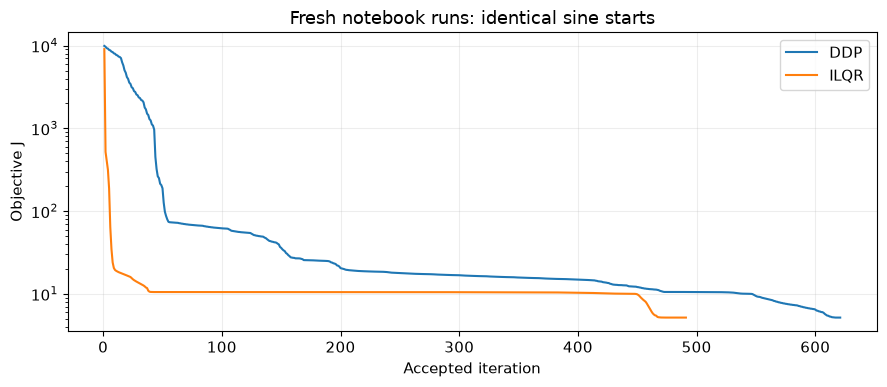

| method | status | steps | cost | solve seconds | terminal error norm | peak torque (N m) |
| --- | --- | --- | --- | --- | --- | --- |
| ddp | converged | 621 | 5.17531 | 2.59667 | 1.86679e-07 | 26.9693 |
| ilqr | converged | 491 | 5.17531 | 0.835461 | 1.86701e-07 | 26.9685 |

In [11]:
rows = []
fig, ax = plt.subplots()
for method, result in solutions.items():
    history = result['history']
    ax.semilogy([h['iteration'] for h in history], [h['cost'] for h in history], label=method.upper())
    accepted_costs = [h['cost'] for h in history]
    assert np.all(np.diff(accepted_costs) < 0)
    rows.append({'method': method, 'status': result['status'], 'steps': result['iterations'],
                 'cost': result['cost'], 'solve seconds': result['seconds'],
                 'terminal error norm': np.linalg.norm(result['x'][-1]-np.asarray(GOAL)),
                 'peak torque (N m)': np.max(np.abs(result['u']))})
ax.set(xlabel='Accepted iteration', ylabel='Objective J', title='Fresh notebook runs: identical sine starts')
ax.legend(); fig.tight_layout(); display(fig); plt.close(fig)
show_table(rows)

### Inspect the final accepted steps and final gain shapes

`relative_drop` is $(J_{old}-J_{new})/\max(1,|J_{old}|)$.
`correction` is $\max|k|$ before scaling by `alpha`. A small `alpha` is not
equivalent to a small unscaled correction. `gains` must correspond to the
returned final states and controls, which is why `solve` recomputes them.

In [12]:
show_table(solutions['ddp']['history'][-5:])
print('Final gains shape:', solutions['ddp']['gains'].shape)
print('Final gain regularization:', solutions['ddp']['gain_regularization'])
assert solutions['ddp']['gains'].shape == (cfg.n, 1, 4)

| iteration | cost | relative_drop | correction | alpha | regularization |
| --- | --- | --- | --- | --- | --- |
| 617 | 5.17722 | 0.00211174 | 2.1616 | 1 | 5.48005e-05 |
| 618 | 5.1754 | 0.000351502 | 0.913807 | 1 | 1.82668e-05 |
| 619 | 5.17531 | 1.77009e-05 | 0.253042 | 1 | 6.08895e-06 |
| 620 | 5.17531 | 4.24083e-08 | 0.0107594 | 1 | 2.02965e-06 |
| 621 | 5.17531 | 4.09671e-12 | 0.000109465 | 1 | 6.7655e-07 |

Final gains shape: (300, 1, 4)
Final gain regularization: 1e-09


## 9. View the optimized motion variables

The plotted plan stops at the end of the swing-up horizon. It does not include
the extra upright holding controller, which is explained in Notebook 3.

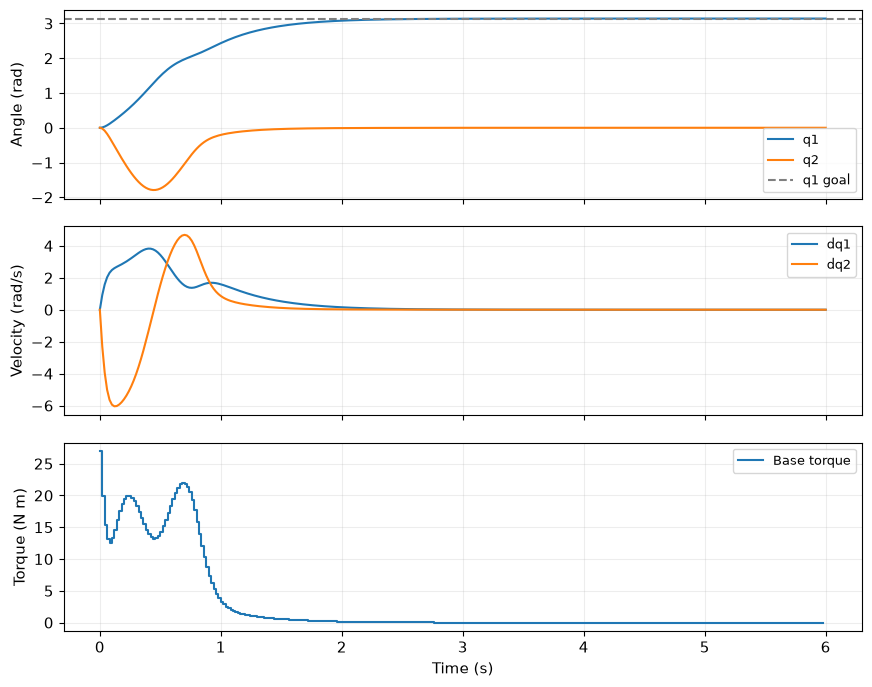

In [13]:
best = solutions[min(solutions, key=lambda key: solutions[key]['cost'])]
t_state = np.arange(cfg.n+1)*cfg.dt
fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True)
axes[0].plot(t_state, best['x'][:, :2], label=['q1', 'q2'])
axes[0].axhline(np.pi, color='gray', ls='--', label='q1 goal')
axes[1].plot(t_state, best['x'][:, 2:], label=['dq1', 'dq2'])
axes[2].step(t_control, best['u'][:, 0], where='post', label='Base torque')
for ax, label in zip(axes, ['Angle (rad)', 'Velocity (rad/s)', 'Torque (N m)']):
    ax.set_ylabel(label); ax.legend(fontsize=9)
axes[2].set_xlabel('Time (s)')
fig.tight_layout(); display(fig); plt.close(fig)

## Experiments to try

- Change `r` from 0.01 to 0.02 in Section 1 and rerun all subsequent cells.
- Replace `u_initial` by zeros and compare both methods from that same guess.
- Set `max_iterations=100`; inspect status instead of assuming convergence.
- Change one state weight at a time and record cost, terminal error, and peak torque.

These are local optimization methods. This notebook does not claim global optimality
or a universal speed ordering between DDP and iLQR. Next:
**03_Feedback_Results_and_Dashboard.ipynb**. Sources: `../pendubot.py`, `../DERIVATION.txt`.